# Корреляционный анализ brainsize.txt

Эксперименты: scatter-графики признаков vs `MRI_Count` и heatmap корреляций

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

## 1. Загрузка данных

In [2]:
df = pd.read_csv("brainsize.txt", sep="\t", na_values="NA")
print(df.shape)
df.head()

(40, 7)


,Gender,FSIQ,VIQ,PIQ,Weight,Height,MRI_Count
0,Female,133,132,124,118.0,64.5,816932
1,Male,140,150,124,NaN,72.5,1001121
2,Male,139,123,150,143.0,73.3,1038437
3,Male,133,129,128,172.0,68.8,965353
4,Female,137,132,134,147.0,65.0,951545


In [3]:
print(df["Gender"].value_counts())
print("\nПропуски:")
print(df.isnull().sum())

Gender
Female    20
Male      20
Name: count, dtype: int64

Пропуски:
Gender       0
FSIQ         0
VIQ          0
PIQ          0
Weight       2
Height       1
MRI_Count    0
dtype: int64


In [4]:
FEATURES = ["FSIQ", "VIQ", "PIQ", "Weight", "Height"]
TARGET = "MRI_Count"

men = df[df["Gender"] == "Male"].copy()
women = df[df["Gender"] == "Female"].copy()

print(f"Мужчины: {len(men)}, Женщины: {len(women)}")

Мужчины: 20, Женщины: 20


## 2. Корреляции Пирсона с MRI_Count

In [5]:
def mri_correlations(group: pd.DataFrame) -> pd.Series:
    return group[FEATURES].corrwith(group[TARGET], method="pearson")

men_corr = mri_correlations(men)
women_corr = mri_correlations(women)

corr_table = pd.DataFrame({"Male": men_corr, "Female": women_corr})
corr_table["|Male|"] = corr_table["Male"].abs()
corr_table["|Female|"] = corr_table["Female"].abs()
corr_table

,Male,Female,|Male|,|Female|
FSIQ,0.498369,0.325697,0.498369,0.325697
VIQ,0.413105,0.254933,0.413105,0.254933
PIQ,0.568237,0.396157,0.568237,0.396157
Weight,-0.076875,0.446271,0.076875,0.446271
Height,0.301543,0.174541,0.301543,0.174541


## 3. Scatter-графики: признаки vs MRI_Count

Отдельно для мужчин и женщин, с линией тренда.

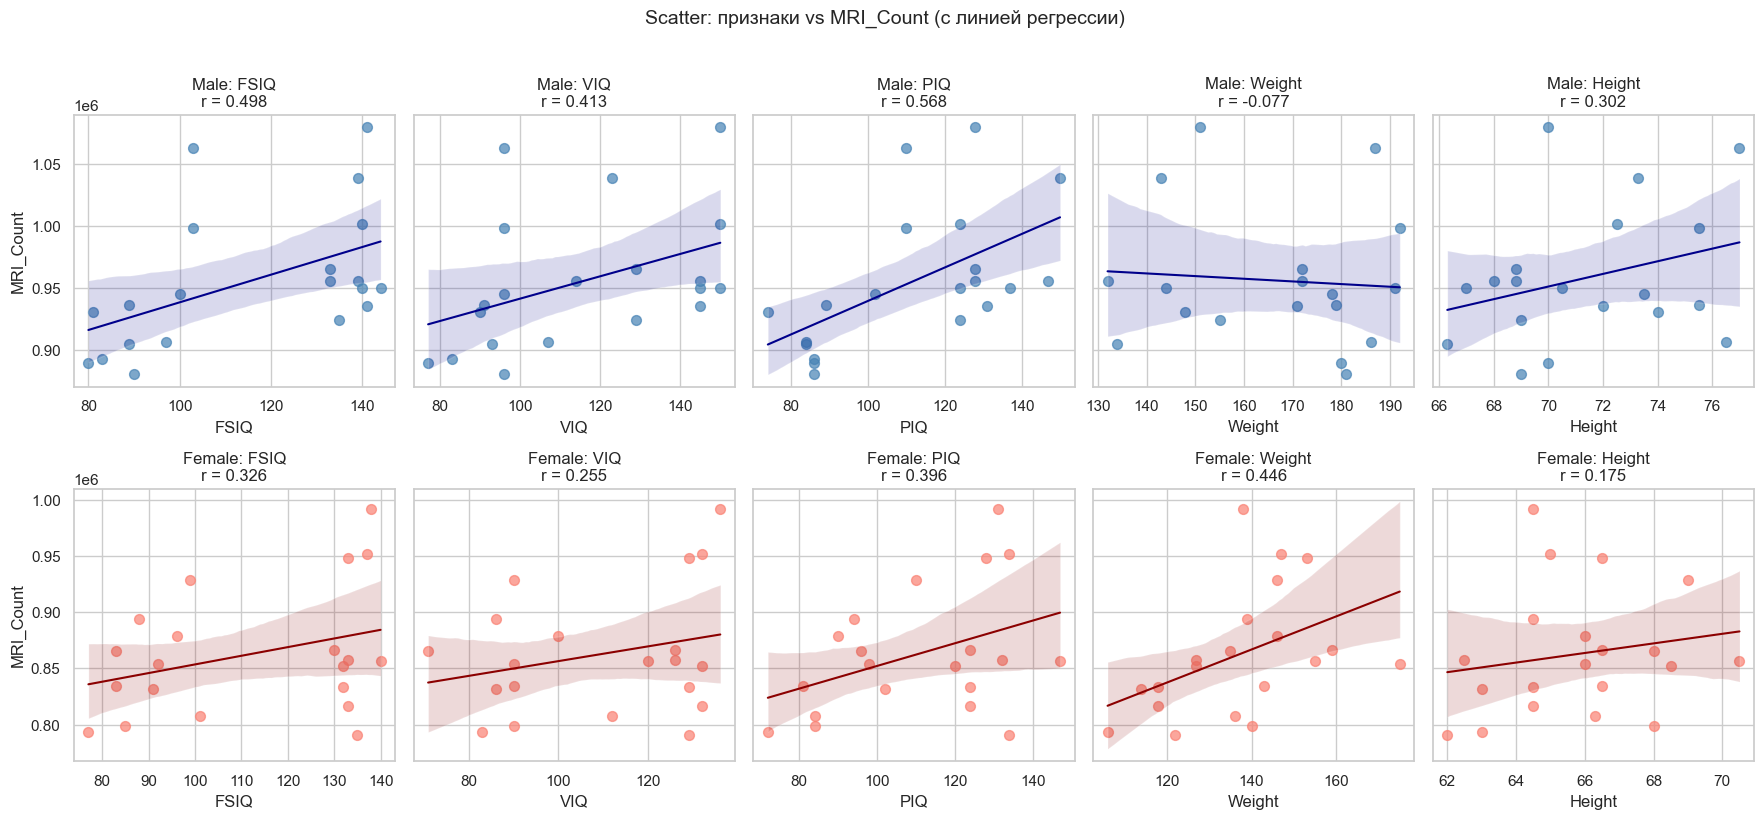

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8), sharey="row")

for col, feat in enumerate(FEATURES):
    # Мужчины
    ax_m = axes[0, col]
    sns.regplot(
        data=men, x=feat, y=TARGET,
        ax=ax_m, color="steelblue",
        scatter_kws={"alpha": 0.7, "s": 50},
        line_kws={"color": "darkblue", "lw": 1.5},
    )
    r = men_corr[feat]
    ax_m.set_title(f"Male: {feat}\nr = {r:.3f}")
    ax_m.set_xlabel(feat)
    if col == 0:
        ax_m.set_ylabel(TARGET)
    else:
        ax_m.set_ylabel("")

    # Женщины
    ax_w = axes[1, col]
    sns.regplot(
        data=women, x=feat, y=TARGET,
        ax=ax_w, color="salmon",
        scatter_kws={"alpha": 0.7, "s": 50},
        line_kws={"color": "darkred", "lw": 1.5},
    )
    r = women_corr[feat]
    ax_w.set_title(f"Female: {feat}\nr = {r:.3f}")
    ax_w.set_xlabel(feat)
    if col == 0:
        ax_w.set_ylabel(TARGET)
    else:
        ax_w.set_ylabel("")

fig.suptitle("Scatter: признаки vs MRI_Count (с линией регрессии)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 4. Heatmap корреляций

Полная матрица корреляций Пирсона для выбранных признаков + `MRI_Count`.

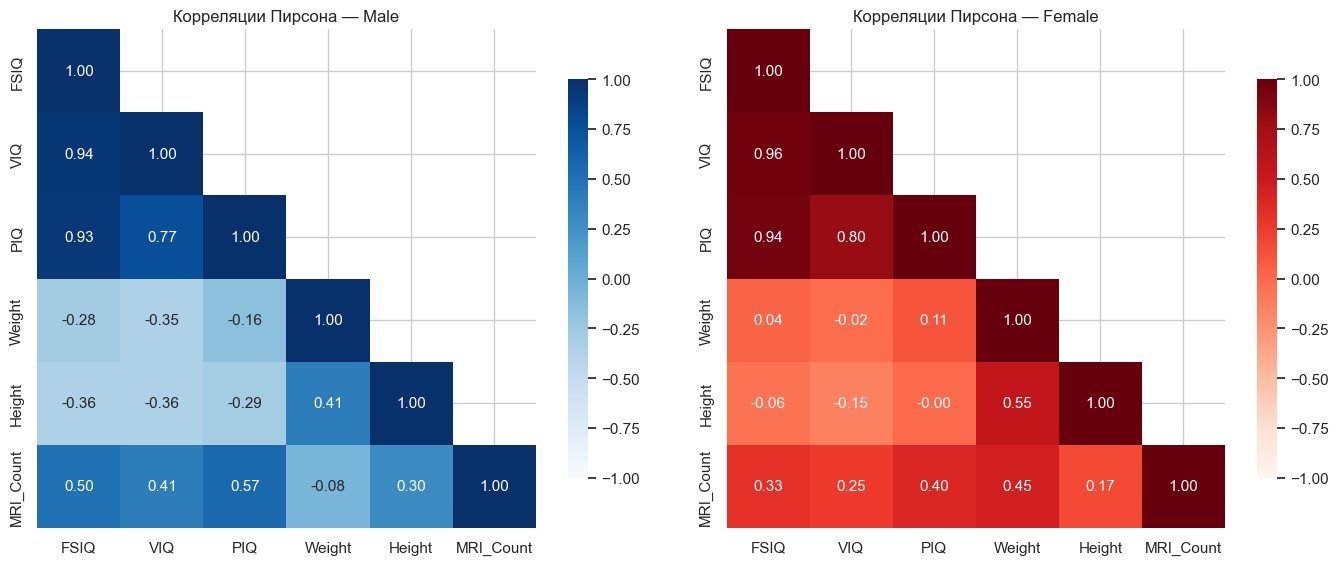

In [7]:
cols = FEATURES + [TARGET]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, group, title, cmap in [
    (axes[0], men, "Male", "Blues"),
    (axes[1], women, "Female", "Reds"),
]:
    corr = group[cols].corr(method="pearson")
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(
        corr,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap=cmap,
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        ax=ax,
        cbar_kws={"shrink": 0.8},
    )
    ax.set_title(f"Корреляции Пирсона — {title}")

plt.tight_layout()
plt.show()

## 5. Сводный heatmap: только корреляции с MRI_Count

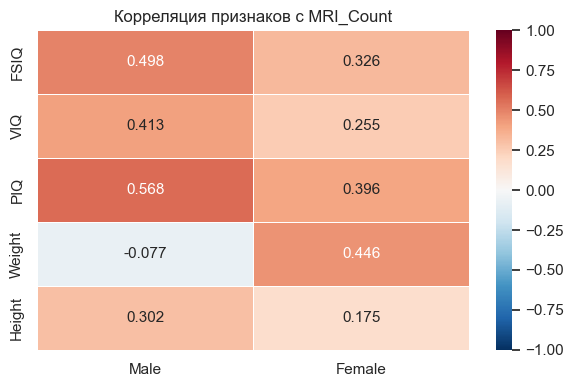

In [8]:
summary = pd.DataFrame({"Male": men_corr, "Female": women_corr})

plt.figure(figsize=(6, 4))
sns.heatmap(
    summary,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Корреляция признаков с MRI_Count")
plt.tight_layout()
plt.show()

## 6. Краткий вывод

- У мужчин наиболее сильная корреляция с `MRI_Count` у **PIQ** (≈ 0.57).
- У женщин наибольший модуль корреляции у **Weight** (≈ 0.45).
- Среди всех значений максимальный модуль — у **PIQ** у мужчин, поэтому `strongest_mri_feature = "PIQ"`.
- Корреляции в целом умеренные; размер выборки небольшой (по 20 наблюдений в группе), поэтому выводы осторожные.